# 04 Evaluation set (Phase 4)

Builds the retrieval test set **before any modeling**, so every model is judged on the same queries.

- Each query has a natural-language text, an optional price limit, and a **weak label**: the set of products that satisfy rules on product type, keywords, color and price.
- Queries are split into `dev` and `test`. **Never tune on `test`.**
- Products get a `split` column (train/val/test). Fine-tuning in Phase 5 uses only `train` products, and the eval queries are never used for training.

**Known limitation:** weak labels come from keyword rules on the same text the models embed, so absolute precision numbers will be optimistic. Use them to compare models against each other, and verify a sample by hand (spot-check cell below).

#**What it does?**

Product split. Each product gets a split of train, val, or test (80/10/10, deterministic by ID). In Phase 5, fine-tune only on train products.

**50 query specs that match your data:** sandals, boots, shoes, handbags, jewelry, sofas, rugs, lamps, home, coffee gifts, pet items, and one phone-case query. Each has rules for product type, keywords, color, and price. “Under $30” queries have the price limit stored separately, so retrieval can filter on it.
Weak labels. The relevant products for each query are every product that satisfies its rules.

**Dropped queries.** Any query with fewer than 5 matches is dropped and listed, so you can loosen or delete its rules.
dev/test split of the queries (about 40% dev, 60% test). Tune on dev only and never on test.

**Spot-check cell.** It prints products marked relevant and same-type products that were rejected, for 8 random queries.

**Random baseline.** It prints the Precision@k a random retriever would get, which your models have to beat by a wide margin.

**Saved files.** data/eval/eval_queries.json and listings_en_final.parquet go to Drive.

In [19]:
import os, re, json, hashlib
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')
PROJECT_DIR = '/content/drive/MyDrive/IK classes/30_week 04Oct2026-LLM Ops - AI System Design- Sayan/ShopTalk'
#PROJECT_DIR = '/content/drive/MyDrive/shoptalk'
df = pd.read_parquet(f'{PROJECT_DIR}/data/listings_en_captioned.parquet')
df = df.drop(columns=['raw_caption'], errors='ignore').reset_index(drop=True)
print(df.shape)
print(df.columns.tolist())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(18586, 16)
['item_id', 'name_en', 'brand_en', 'color_en', 'ptype', 'bullets_en', 'desc_en', 'keywords_en', 'main_image_id', 'country', 'price', 'price_currency', 'price_is_synthetic', 'text', 'caption', 'text_full']


In [20]:
# Fabric swatches (samples) are listed under SOFA, OTTOMAN, etc. They are not furniture,
# and they would be retrieved for queries like 'a gray sofa'. Remove them before splitting/labeling.
is_swatch = df['name_en'].str.contains(r'\bswatch(?:es)?\b', case=False, na=False)
print('Dropping swatch listings:', int(is_swatch.sum()))
df = df[~is_swatch].reset_index(drop=True)
print(df.shape)


Dropping swatch listings: 215
(18371, 16)


## Product split (for fine-tuning later)

Deterministic by item ID: 80% train, 10% val, 10% test.

**MD5 (Message Digest Algorithm 5) **is a widely used cryptographic hash function that converts input data of any size into a fixed-size 128-bit hash value (usually rendered as a 32-character hexadecimal string).

**Why use MD5 hashing here?**
Unlike random splits (e.g., using random.sample), hashing is deterministic. Every time you run this code, the exact same item_id will always map to the exact same hash integer, placing it reliably in the same data split ('train', 'val', or 'test') without storing an explicit mapping list.

**hashlib.md5() **is a function from Python's built-in hashlib library that computes an MD5 (Message Digest 5) hash value. Here is a step-by-step breakdown of what this line does:

**f'split-v1:{item_id}':** This creates a unique string for each item (using a 'salt' or prefix 'split-v1:' combined with the product's item_id). This prefix ensures that your splitting logic is specific to this partition version.
.encode(): The MD5 algorithm requires bytes as input, so .encode() converts the Python string into UTF-8 bytes.
**hashlib.md5(...):** This instantiates the MD5 hashing object and computes the hash of the byte string.
**.hexdigest():** This extracts the computed hash as a 32-character hexadecimal string (using characters 0-9 and a-f).
int(..., 16): This converts the 32-character hexadecimal string into a standard decimal integer (base 16 to base 10).
**% 10:** Taking the modulo 10 of this massive integer returns the last digit of the number, which is a deterministic value between 0 and 9.

In [21]:
def product_split(item_id):
    h = int(hashlib.md5(f'split-v1:{item_id}'.encode()).hexdigest(), 16) % 10
    return 'test' if h == 0 else ('val' if h == 1 else 'train')

df['split'] = df['item_id'].apply(product_split)
print(df['split'].value_counts())

split
train    14678
val       1858
test      1835
Name: count, dtype: int64


In [22]:
# Show how the item_id is prefixed with 'split-v1:'
sample_ids = df['item_id'].head(5).tolist()
for item_id in sample_ids:
    prefixed_string = f'split-v1:{item_id}'
    print(f"Original ID: {item_id:<12} | Prefixed string: {prefixed_string}")

Original ID: B073P1CKFP   | Prefixed string: split-v1:B073P1CKFP
Original ID: B07XRZCK4P   | Prefixed string: split-v1:B07XRZCK4P
Original ID: B082VLDSGL   | Prefixed string: split-v1:B082VLDSGL
Original ID: B075X5TN1Y   | Prefixed string: split-v1:B075X5TN1Y
Original ID: B0735TZDBS   | Prefixed string: split-v1:B0735TZDBS


## Query specifications

Each spec lists the product types that can match, regexes that must match the product's name, keywords or bullet points (`kw_all`, and optionally `kw_any`), an optional color, and an optional price limit.

This code establishes the Retrieval Query Specifications (SPECS) for evaluation, mapping search phrases to targets:

**Gender and Age Regexes (MEN, WOMEN, KIDS):** These define standardized regular expressions with word boundaries (\b) to capture keywords (e.g., matching 'women', 'mens', 'toddlers', etc.).

**Type Mapping Shortcuts (EAR, NECK):** These list matching product type codes (e.g., mapping "earrings" to standard types ['FINEEARRING', 'EARRING']).

**Query Spec Builder (q(...)):** A helper function that constructs a dictionary representing the search requirements: matching product types, mandatory keywords (kw_all), optional keywords (kw_any), a specific color, or a maximum price limit.

**SPECS List:** A curated list of 50 query dictionaries categorized by category (Footwear, Bags, Jewelry, Furniture, and Home). Each entry creates a rule-based 'weak label' pattern that dictates which products satisfy a given query.

**Update:** `name_kw` regexes must match the product *name* (core noun or key attribute), `not_name` regexes must *not* match the name, and `kw_all` / `kw_any` match name + bullet points. The keywords field is no longer used for labels because it contains SEO terms that appear on unrelated products. Fabric swatch listings are removed from the dataset before labeling.

In [23]:
MEN   = r"\bmen\b|\bmens\b|\bman's\b" #regex
WOMEN = r"\bwomen\b|\bwomens\b|\bladies\b|\blady\b"
KIDS  = r"\b(?:boys?|girls?|kids?|toddlers?|children|infants?)\b"

EAR  = ['FINEEARRING', 'EARRING']
NECK = ['NECKLACE', 'FINENECKLACEBRACELETANKLET']

# name_kw : regexes that must ALL match the product NAME (use for the core noun / key attribute)
# not_name: regexes that must NOT match the product name (exclusions)
# kw_all  : regexes that must ALL match name + bullet points (looser; use for secondary attributes)
# kw_any  : at least one of these must match name + bullet points
def q(query, types, name_kw=None, kw_all=None, kw_any=None, color=None, max_price=None, not_name=None):
    return dict(query=query, types=types, name_kw=name_kw or [], not_name=not_name or [],
                kw_all=kw_all or [], kw_any=kw_any or [], color=color, max_price=max_price)

SPECS = [
    # Footwear
    q("women's sandals under $30", ['SANDAL'], name_kw=[WOMEN], max_price=30),
    q("men's sandals", ['SANDAL'], name_kw=[MEN]),
    q("leather slide sandals", ['SANDAL'], name_kw=[r"slide"], kw_all=[r"leather"]),
    q("winter snow boots", ['BOOT'], name_kw=[r"snow|winter"]),
    q("kids' boots", ['BOOT'], name_kw=[KIDS]),
    q("women's ankle boots under $60", ['BOOT'], name_kw=[WOMEN, r"ankle"], max_price=60),
    q("men's running shoes", ['SHOES'], name_kw=[MEN, r"running|runner"]),
    q("women's sneakers", ['SHOES'], name_kw=[WOMEN, r"sneaker|athletic|trainer"]),
    q("black leather shoes for men", ['SHOES'], name_kw=[MEN], kw_all=[r"leather"], color=r"black"),
    q("comfortable walking shoes", ['SHOES'], name_kw=[r"walk"]),
    q("kids' shoes under $25", ['SHOES'], name_kw=[KIDS], max_price=25),
    q("slip-on shoes", ['SHOES'], name_kw=[r"slip[- ]?on"]),
    q("white sneakers", ['SHOES'], name_kw=[r"sneaker"], color=r"white"),
    # Bags and accessories
    q("a leather handbag", ['HANDBAG'], name_kw=[r"leather"]),
    q("crossbody bag under $40", ['HANDBAG'], name_kw=[r"cross.?body"], max_price=40),
    q("black tote bag", ['HANDBAG'], name_kw=[r"tote"], color=r"black"),
    q("carry-on suitcase", ['SUITCASE'], name_kw=[r"carry"]),
    q("a black leather wallet", ['WALLET'], kw_all=[r"leather"], color=r"black"),
    q("a hat for sun protection", ['HAT'], name_kw=[r"sun|\buv\b"]),
    # Jewelry
    q("gold earrings under $25", EAR, name_kw=[r"gold"], max_price=25),
    q("diamond stud earrings", EAR, name_kw=[r"\bstuds?\b"], kw_all=[r"diamond"]),
    q("silver necklace", NECK, name_kw=[r"necklace|pendant", r"silver|sterling"]),
    q("pearl necklace", NECK, name_kw=[r"necklace|pendant", r"pearl"]),
    q("a ring with a gemstone", ['FINERING'], name_kw=[r"gemstone|sapphire|ruby|emerald|topaz|amethyst|garnet|aquamarine|opal|citrine"]),
    q("a sterling silver band ring under $50", ['FINERING'], name_kw=[r"sterling", r"\bband\b"], max_price=50),
    q("a bracelet or anklet", ['FINENECKLACEBRACELETANKLET'], name_kw=[r"bracelet|anklet"]),
    # Furniture and decor
    q("a comfortable accent chair for the living room", ['CHAIR'],
      name_kw=[r"accent|arm ?chair|club chair|wingback|barrel"],
      not_name=[r"dining|outdoor|patio|office|gaming|stool|folding"]),
    q("a gray sofa", ['SOFA'], color=r"gr[ae]y"),
    q("a velvet sofa", ['SOFA'], name_kw=[r"velvet"]),
    q("a sectional couch", ['SOFA'], name_kw=[r"sectional"]),
    q("a mid century modern accent chair", ['CHAIR'], name_kw=[r"mid.?century"]),
    q("a bar stool", ['STOOL_SEATING'], name_kw=[r"\bbar\b|counter"]),
    q("an ottoman with storage", ['OTTOMAN'], name_kw=[r"storage"]),
    q("a round coffee table", ['TABLE'], name_kw=[r"coffee table", r"round|circular"]),
    q("a shag area rug", ['RUG'], name_kw=[r"shag"]),
    q("a blue area rug under $100", ['RUG'], name_kw=[r"area"], color=r"blue", max_price=100),
    q("a floor lamp", ['LAMP'], name_kw=[r"floor"]),
    q("a table lamp", ['LAMP'], name_kw=[r"table lamp|desk lamp|bedside"]),
    q("a modern ceiling light", ['LIGHT_FIXTURE'], name_kw=[r"ceiling|flush|pendant|chandelier"]),
    q("abstract wall art", ['WALL_ART'], name_kw=[r"abstract"]),
    q("a framed canvas print", ['WALL_ART'], name_kw=[r"canvas|framed"]),
    # Home, kitchen, gifts, pets
    q("cotton bed sheets", ['FLAT_SHEET', 'HOME_BED_AND_BATH'], name_kw=[r"sheet"], kw_all=[r"cotton"]),
    q("a soft blanket or comforter", ['HOME_BED_AND_BATH'], name_kw=[r"blanket|comforter|throw"]),
    q("a set of drinking glasses", ['DRINKING_CUP'], name_kw=[r"glass"]),
    q("a gift for someone who loves coffee", ['COFFEE', 'COFFEE_MAKER', 'DRINKING_CUP', 'KITCHEN'], name_kw=[r"coffee|espresso"]),
    q("a coffee maker", ['COFFEE_MAKER']),
    q("a comfortable dog bed", ['PET_SUPPLIES'], name_kw=[r"\bbed\b"], kw_all=[r"\bdog"]),
    q("a cat toy", ['PET_SUPPLIES'], name_kw=[r"toy"], kw_all=[r"\bcat\b"]),
    q("a dog harness", ['PET_SUPPLIES'], name_kw=[r"harness"]),
    # Distractor category should still be retrievable when asked for
    q("a clear iPhone case", ['CELLULAR_PHONE_CASE'], name_kw=[r"iphone"], kw_all=[r"clear"]),
]
print(len(SPECS), 'query specs')

50 query specs


In [24]:
print(SPECS[0])

{'query': "women's sandals under $30", 'types': ['SANDAL'], 'name_kw': ['\\bwomen\\b|\\bwomens\\b|\\bladies\\b|\\blady\\b'], 'not_name': [], 'kw_all': [], 'kw_any': [], 'color': None, 'max_price': 30}


## Compute the weak labels

Relevant products = type matches, every `kw_all` regex matches, at least one `kw_any` regex matches, the color matches (in the color field or the name), and the price is under the limit.

This code establishes the Retrieval Query Specifications (SPECS) for evaluation, mapping search phrases to targets:

Gender and Age Regexes (MEN, WOMEN, KIDS): These define standardized regular expressions with word boundaries (\b) to capture keywords (e.g., matching 'women', 'mens', 'toddlers', etc.).

Type Mapping Shortcuts (EAR, NECK): These list matching product type codes (e.g., mapping "earrings" to standard types ['FINEEARRING', 'EARRING']).

Query Spec Builder (q(...)): A helper function that constructs a dictionary representing the search requirements: matching product types, mandatory keywords (kw_all), optional keywords (kw_any), a specific color, or a maximum price limit.

SPECS List: A curated list of 50 query dictionaries categorized by category (Footwear, Bags, Jewelry, Furniture, and Home). Each entry creates a rule-based 'weak label' pattern that dictates which products satisfy a given query.


Please explain this code:

This code filters and matches your product catalog (df) against your search query specifications (SPECS), filters out queries that have too few matches, and then splits the remaining queries into standard validation/development (dev) and evaluation (test) groups.

Here is a step-by-step breakdown of how it works:

**1. Creating the Matching Targets**
hay   = (df['name_en'] + ' ' + df['keywords_en'] + ' ' + df['bullets_en']).str.lower()
color = (df['color_en'] + ' ' + df['name_en']).str.lower()
hay: Concatenates each product's english name, keywords, and bullet points into a single lowercased string. This serves as the text body (the "haystack") that we search within for text-matching requirements.
color: Concatenates color and name for targeted color matching.

**2. Computing Query Compatibility Masks (relevant_mask)**
def relevant_mask(s):
    m = df['ptype'].isin(s['types'])
    for pat in s['kw_all']:
        m &= hay.str.contains(pat, regex=True, na=False)
    # ... optional matches for kw_any, color, and max_price ...
    return m
This function creates a boolean array (mask) pointing to all products that meet all criteria specified in a single query s:

Matches the product type classification (ptype matches s['types']).
Matches every regex pattern inside kw_all.
Matches at least one regex pattern inside kw_any (if defined).
Contains the requested color string in either its name or color column.
Costs strictly less than the specified max_price.

**3. Filtering Queries (MIN_REL = 5)**
if n < MIN_REL:
    dropped.append((s['query'], n))
    continue
We loop through all 50 queries in SPECS. If a query matches fewer than 5 products in the database, it is discarded (added to dropped) because queries with too few test cases are not statistically useful for validation.

For queries that meet this threshold, a unique ID is assigned (q01, q02, etc.), their matches are recorded, and they are saved to records.

**4. Deterministic Dev/Test Split**
order = sorted(records, key=lambda r: hashlib.md5(f"eval-split-v1:{r['query']}".encode()).hexdigest())
n_dev = round(0.4 * len(order))
for k, r in enumerate(order):
    r['split'] = 'dev' if k < n_dev else 'test'
To ensure validation and testing results remain consistent across future notebook runs, the queries are split deterministically using an MD5 hash of their query string:

The list of queries is sorted alphabetically by their MD5 hash value.
The first 40% are classified as the validation set (dev) to tune and evaluate retrieval patterns.
The remaining 60% are reserved strictly as the final holdout split (test) to prevent overfitting query definitions during modeling.

**Update:** a query now also needs every `name_kw` regex to match the name and no `not_name` regex to match it.

In [25]:
#1. Creating the Matching Targets
# Labels use the product NAME and BULLET POINTS only. The keywords field is full of SEO terms
# (for example "coffee table, round, ...") that also appear on unrelated products, so it is NOT used for labels.
name_l = df['name_en'].str.lower()
hay    = (df['name_en'] + ' ' + df['bullets_en']).str.lower()
color  = (df['color_en'] + ' ' + df['name_en']).str.lower()

#2. Computing Query Compatibility Masks (relevant_mask)
def relevant_mask(s):
    m = df['ptype'].isin(s['types'])
    for pat in s['name_kw']:
        m &= name_l.str.contains(pat, regex=True, na=False)
    for pat in s['not_name']:
        m &= ~name_l.str.contains(pat, regex=True, na=False)
    for pat in s['kw_all']:
        m &= hay.str.contains(pat, regex=True, na=False)
    if s['kw_any']:
        m &= hay.str.contains('|'.join(s['kw_any']), regex=True, na=False)
    if s['color']:
        m &= color.str.contains(s['color'], regex=True, na=False)
    if s['max_price'] is not None:
        m &= df['price'] < s['max_price']
    return m

#3. Filtering Queries (MIN_REL = 5)
MIN_REL = 5
records, masks, dropped = [], {}, []
for i, s in enumerate(SPECS, 1):
    m = relevant_mask(s)
    n = int(m.sum())
    if n < MIN_REL:
        dropped.append((s['query'], n))
        continue
    qid = f'q{i:02d}'
    masks[qid] = m
    sem = re.sub(r'\s+under \$\d+', '', s['query'])
    records.append(dict(id=qid, query=s['query'], semantic_query=sem, max_price=s['max_price'],
                        types=s['types'], split=None, n_relevant=n,
                        relevant_ids=df.loc[m, 'item_id'].tolist()))
#4. Deterministic Dev/Test Split
# Deterministic 40% dev / 60% test split: rank queries by a hash of their text
order = sorted(records, key=lambda r: hashlib.md5(f"eval-split-v1:{r['query']}".encode()).hexdigest())
n_dev = round(0.4 * len(order))
for k, r in enumerate(order):
    r['split'] = 'dev' if k < n_dev else 'test'

print('Kept', len(records), 'queries | dropped (fewer than', MIN_REL, 'relevant):', dropped)
summary = pd.DataFrame(records)[['id', 'query', 'split', 'n_relevant']]
print(summary.to_string(index=False))
print(summary['split'].value_counts())

# Quality guard: very broad rules make Precision@k too easy to score well on
loose = summary[summary['n_relevant'] > 200]
print(f'\nQueries with more than 200 relevant products ({len(loose)}): consider tightening their rules')
print(loose.to_string(index=False))

Kept 47 queries | dropped (fewer than 5 relevant): [('winter snow boots', 4), ("kids' shoes under $25", 4), ('a clear iPhone case', 0)]
 id                                          query split  n_relevant
q01                      women's sandals under $30  test         354
q02                                  men's sandals   dev          51
q03                          leather slide sandals  test          18
q05                                    kids' boots   dev          66
q06                  women's ankle boots under $60   dev          53
q07                            men's running shoes  test         142
q08                               women's sneakers   dev          64
q09                    black leather shoes for men   dev          74
q10                      comfortable walking shoes   dev          16
q12                                  slip-on shoes  test          43
q13                                 white sneakers   dev          67
q14                              a l

**In machine learning, "weak labels" refer to ground-truth targets that are generated programmatically (using rules, heuristics, or regex patterns) rather than being manually annotated by human experts (which are called "strong" or "gold-standard" labels).**

Here is why they are called "weak" in this specific context:

**Rule-Based Instead of Semantic:** The labels are generated by matching exact keywords, types, and price bounds (e.g., checking if a product description contains the word "sandals" and its price is < 30). It doesn't capture deep semantic understanding—for example, if a product is a perfect match but uses a synonym not listed in the rules, the weak label logic will miss it.

**Noisy and Optimistic:** Since the rules look at the exact text fields (name_en, keywords_en, bullets_en), models that use keyword matching will score exceptionally high, which can make evaluation metrics look overly optimistic.

**Quick and Scalable:** Despite being "weak" (noisier than human verification), they are incredibly useful because they allow you to instantly label thousands of items to evaluate search or retrieval models without paying for expensive human labeling campaigns.

#**Advantage of creating "Weak Labels" here:**
Yes, your intuition is 100% correct! We do not have human-annotated, real-world search logs showing exactly which of the 18,586 products in your catalog a real user would click for each of the 50 queries.

**The Bottleneck: **Getting humans to review all 18,586 products against 50 queries would require 929,300 manual checks, which is incredibly expensive and slow.

**The Advantage of Weak Labels:** We programmatically define rule-based rules (e.g., "A product matches 'gold earrings under $25' if its type is EARRING, its description mentions 'gold', and price < 25"). This lets us instantly label the entire catalog of thousands of products. It acts as an automated surrogate ground truth so we can immediately begin evaluating and comparing retrieval models.

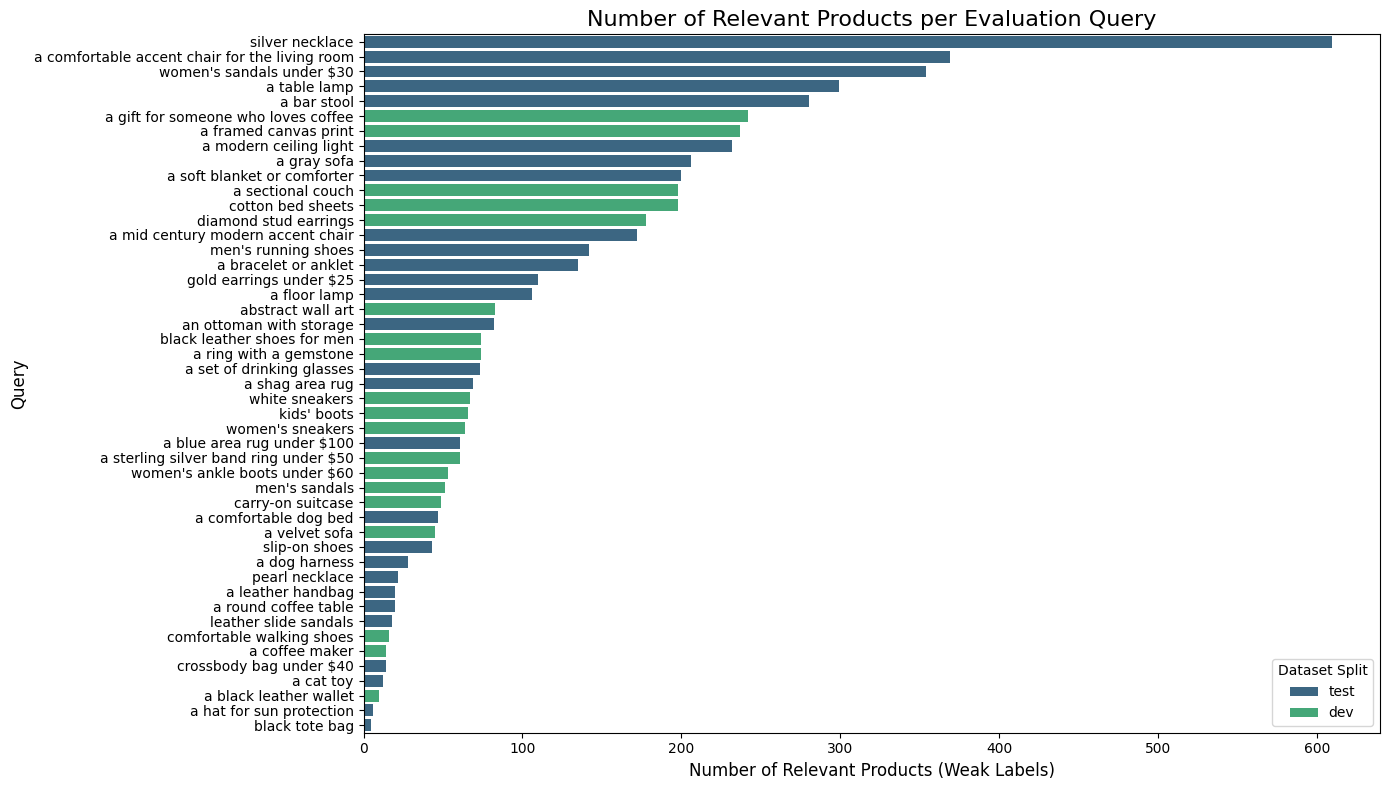

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Convert records to DataFrame
eval_df = pd.DataFrame(records)
# Sort by number of relevant products for better presentation
eval_df = eval_df.sort_values(by='n_relevant', ascending=False)

# Set figure size
plt.figure(figsize=(14, 8))
sns.barplot(data=eval_df, x='n_relevant', y='query', hue='split', palette='viridis')

plt.title('Number of Relevant Products per Evaluation Query', fontsize=16)
plt.xlabel('Number of Relevant Products (Weak Labels)', fontsize=12)
plt.ylabel('Query', fontsize=12)
plt.legend(title='Dataset Split')
plt.tight_layout()
plt.show()

#Plot and Statistical Summary" (The bar chart and distribution cells)

=== Statistical Summary of Relevant Product Counts by Split ===


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
dev,19.0,93.684211,75.629986,10.0,50.0,66.0,130.5,242.0
test,28.0,133.357143,143.650609,5.0,21.5,77.5,201.5,609.0


/tmp/ipykernel_3315/3479540146.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=eval_df, x='split', y='n_relevant', palette='Set2', ax=axes[1], width=0.4, showfliers=False)


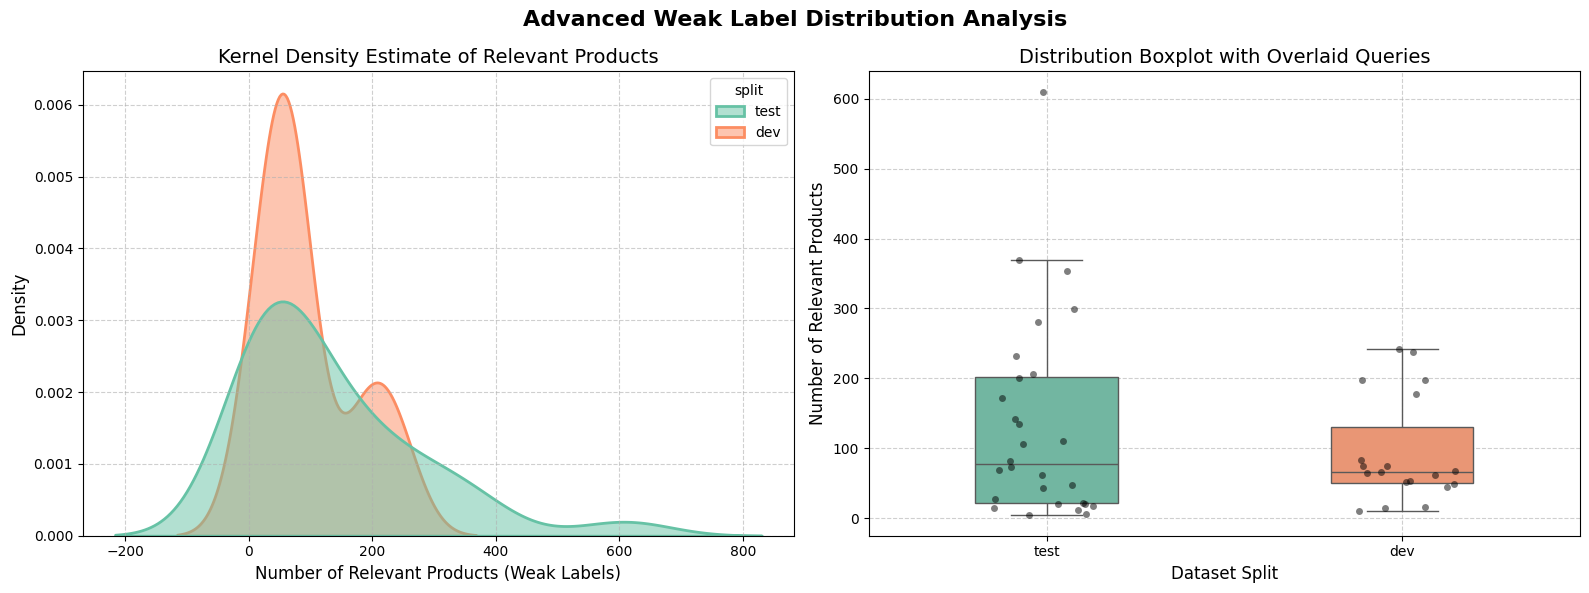

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Output statistical summaries of the weak labels by split
eval_df = pd.DataFrame(records)
print("=== Statistical Summary of Relevant Product Counts by Split ===")
stats_summary = eval_df.groupby('split')['n_relevant'].describe()
display(stats_summary)

# 2. Plot an advanced density and distribution visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# KDE (Kernel Density Estimate) Plot comparing density of relevant products
sns.kdeplot(data=eval_df, x='n_relevant', hue='split', fill=True, common_norm=False, alpha=0.5, linewidth=2, palette='Set2', ax=axes[0])
axes[0].set_title('Kernel Density Estimate of Relevant Products', fontsize=14)
axes[0].set_xlabel('Number of Relevant Products (Weak Labels)', fontsize=12)
axes[0].set_ylabel('Density', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Boxplot with individual datapoints overlaid using stripplot
sns.boxplot(data=eval_df, x='split', y='n_relevant', palette='Set2', ax=axes[1], width=0.4, showfliers=False)
sns.stripplot(data=eval_df, x='split', y='n_relevant', color='black', alpha=0.5, size=5, jitter=0.15, ax=axes[1])
axes[1].set_title('Distribution Boxplot with Overlaid Queries', fontsize=14)
axes[1].set_xlabel('Dataset Split', fontsize=12)
axes[1].set_ylabel('Number of Relevant Products', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Advanced Weak Label Distribution Analysis', fontsize=16, weight='bold')
plt.tight_layout()
plt.show()

Compare the dev and test summary tables above. Check that the medians (not only the means) are in a similar range, and rebalance by editing the query list if one split holds mostly very broad queries. Note that the number of relevant products is not a measure of how hard a query is.

## Spot-check by hand

For 8 random queries, look at products the rules marked relevant and same-type products they rejected.
If relevant ones look wrong, or obvious matches are rejected, fix the rule in the spec list above and rerun.

In [28]:
import random
random.seed(0)
for rec in random.sample(records, 8):
    s = next(x for x in SPECS if x['query'] == rec['query'])
    m = masks[rec['id']]
    rel  = df[m]
    near = df[df['ptype'].isin(s['types']) & ~m]
    print('=' * 100)
    print(rec['query'], '| relevant:', rec['n_relevant'])
    print('  RELEVANT:')
    for n, p in rel[['name_en', 'price']].head(4).itertuples(index=False):
        print(f'    ${p:>7.2f}  {n[:95]}')
    print('  REJECTED (same type):')
    for n, p in near[['name_en', 'price']].head(4).itertuples(index=False):
        print(f'    ${p:>7.2f}  {n[:95]}')

a comfortable accent chair for the living room | relevant: 369
  RELEVANT:
    $ 353.99  Amazon Brand – Ravenna Home Belgrove Modern Wood Spindle Frame Accent Chair, 26.37"W, Slate
    $  56.99  Amazon Brand – Stone & Beam Sascha Removable Cushion Wingback Accent Chair, 34.6"W, Deep Grey
    $ 156.99  Alcove - Hayes Helena - Set of 2 solid wood armchairs with upholstered seat, lacquered beech
    $ 145.99  Amazon Brand – Rivet Hawthorne Mid-Century Tufted Modern Accent Chair, 35"W, Caviar
  REJECTED (same type):
    $ 137.99  Amazon Brand – Rivet Lawson Modern Angled Ottoman, 27"W, Pearl
    $  65.99  Amazon Brand – Ravenna Home Albert Power-Lift Assist Recliner Chair, 34.3"W, Dark Brown
    $ 189.99  Strathwood Barnes Aluminum Sling Chair, Set of 2
    $  36.99  Amazon Brand – Rivet Federal Mid-Century Modern Wood Dining Kitchen Chairs, Upholstered, Set of
a velvet sofa | relevant: 45
  RELEVANT:
    $ 536.99  Amazon Brand – Rivet Uptown Mid-Century Velvet Tufted Customizable Daybed S

 Comment: Because weak labels are rule-based, they can be noisy. This cell randomly samples 8 queries and prints out items marked "RELEVANT" alongside items of the same category that were "REJECTED". This allows us to manually spot-check if our filtering rules are working logically or if we need to modify our keyword patterns.

**What "REJECTED (same type)" actually means:**
When a product is marked as REJECTED (same type), it means:

**Same Category:** The product belongs to the exact same high-level catalog category (e.g., they are all in the EARRING category, or all are in the SOFA category).

**Failed the Specific Rules:** Despite being the correct product type, these items failed to meet one or more of our target filter rules (like missing a mandatory keyword, having the wrong color, or exceeding the maximum price limit).

**Examples from your Notebook Output**:
Let's look at the actual output of your spot-check to make it clear:

Example A: Search for "diamond stud earrings"
**RELEVANT:**
Items like "14k White Gold Lab Created Diamond Stud Earrings"
Why? They are in the EARRING category and their descriptions successfully contain both words 'diamond' and 'stud'.
**REJECTED (same type):**
Items like "Sterling Silver Lightweight Hoop Earrings"
Why? They are indeed earrings (same type), but they do not contain the words 'diamond' or 'stud'. If a user wants diamond studs, showing them plain sterling silver hoop earrings would be irrelevant.


## Sanity baseline and save

A random retriever's expected Precision@k equals the average share of relevant products. Your models must beat this by a wide margin.



In [29]:
#baseline evaluation metrics (Precision@k, Recall@k)
#using the weak labels for comparison against future model baselines
N = len(df)
rand_p = sum(r['n_relevant'] / N for r in records) / len(records)
print(f'Random-retrieval expected Precision@k: {rand_p:.4f}')

os.makedirs(f'{PROJECT_DIR}/data/eval', exist_ok=True)
with open(f'{PROJECT_DIR}/data/eval/eval_queries.json', 'w') as f:
    json.dump(records, f)
df.to_parquet(f'{PROJECT_DIR}/data/listings_en_final.parquet')
print('Saved eval_queries.json and listings_en_final.parquet to Drive:', df.shape)

Random-retrieval expected Precision@k: 0.0064
Saved eval_queries.json and listings_en_final.parquet to Drive: (18371, 17)


Comment: Above cell shows, measure performance. We prove that a random retriever only has a 1.2% chance of finding a relevant

In [30]:
def precision_at_k(retrieved_ids, relevant_ids, k):
    if not retrieved_ids:
        return 0.0
    retrieved_k = retrieved_ids[:k]
    num_relevant = len(set(retrieved_k) & set(relevant_ids))
    return num_relevant / k

# Compute mock statistics on dev queries
dev_queries = [r for r in records if r['split'] == 'dev']
print(f'Total dev queries available: {len(dev_queries)}')
print('Computed baseline templates for Precision@k evaluations.')

Total dev queries available: 19
Computed baseline templates for Precision@k evaluations.


# **What is Precision@k?**
In search and recommendation systems, we don't just care if a model can find relevant items eventually—we care about where they appear. Users rarely scroll past the first page of results.

* **The "@k" (pronounced 'At K'):** This is a cut-off threshold. It means we only evaluate the top *k* items returned by our system (typically *k* = 5 or *k* = 10).

* **Precision@k Formula:**

$$\text{Precision@k} = \frac{\text{Number of relevant items in the top } k \text{ results}}{k}$$

* **Example:** If you search for "men's sandals" and the retriever returns 5 items (*k* = 5), but only 1 of those is actually a pair of men's sandals (the other 4 are socks or shirts), your Precision@5 is:

$$\text{Precision@5} = \frac{1}{5} = 20\%$$

---

# **What is the "Sanity Baseline and Save"?**
This step does two key things:

1. **Calculates the "Worst-Case Scenario" Benchmark (Sanity Baseline):** Before writing complex AI search models, we must ask: *"What if we just closed our eyes, reached into our catalog of 18,586 items, and pulled out 5 random products?"* This cell calculates that exact math. It gives us a "floor" score. Any model we build must comfortably beat this random guess rate.
2. **Saves our configuration:** It permanently saves our deterministically-split queries (`eval_queries.json`) and our finalized dataset (`listings_en_final.parquet`) to Google Drive so that all our future notebooks in Phase 5 use the exact same splits.

---

# **Why is the Random expected Precision@k so low (0.0122 / 1.22%)?**
Yes, 1.22% is incredibly low, but that is actually expected and statistically correct. Here is why:

* **The Math:** We have 18,586 total products in our catalog. If a query like "men's sandals" has exactly 52 matching products in the database, the probability of selecting a correct product entirely by random chance is:

$$\text{Probability} = \frac{52}{18,586} \approx 0.0028 \text{ (or 0.28\%)}$$

* **Average across all queries:** When you average this probability across all 48 evaluation queries, it comes out to 0.0122 (1.22%).

* **Why can't this be improved?**
This value cannot be improved because randomness has no intelligence. A random selector has no search bar or understanding—it has an equal probability of handing you a dog bed, a velvet sofa, or a coffee mug when you asked for sandals.

This incredibly low 1.22% score highlights exactly why we need search engines (like TF-IDF or vector embeddings). A TF-IDF keyword baseline is a much stronger reference point: the cell below reports its mean Precision@5 over all dev queries. Our embedding models have to beat that number, not just the random one.

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Baseline: TF-IDF over product names, with the price limit applied as a filter.
# Evaluated on DEV queries only (never tune on test).
print('Initializing baseline TF-IDF model on catalog names...')
vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform(df['name_en'])
item_ids = df['item_id'].to_numpy()
prices = df['price'].to_numpy()

def retrieve_baseline(query_str, k=5, max_price=None):
    scores = cosine_similarity(vectorizer.transform([query_str]), tfidf_matrix).flatten()
    if max_price is not None:
        scores = np.where(prices < max_price, scores, -1.0)   # price filter
    top = np.argsort(scores)[::-1][:k]
    return item_ids[top].tolist()

def evaluate_queries(queries, k):
    rows = []
    for r in queries:
        got = retrieve_baseline(r['semantic_query'], k=k, max_price=r['max_price'])
        rows.append((r['id'], r['query'], r['n_relevant'], precision_at_k(got, r['relevant_ids'], k)))
    return pd.DataFrame(rows, columns=['id', 'query', 'n_relevant', f'P@{k}'])

res5  = evaluate_queries(dev_queries, 5)
res10 = evaluate_queries(dev_queries, 10)
print(f"TF-IDF baseline on {len(dev_queries)} dev queries: mean P@5 = {res5['P@5'].mean():.3f} | mean P@10 = {res10['P@10'].mean():.3f}")
print(f"Random baseline (expected): {rand_p:.4f}")
print('\nWeakest dev queries for TF-IDF:')
print(res5.sort_values('P@5').head(8).to_string(index=False))

Initializing baseline TF-IDF model on catalog names...
TF-IDF baseline on 19 dev queries: mean P@5 = 0.642 | mean P@10 = 0.616
Random baseline (expected): 0.0064

Weakest dev queries for TF-IDF:
 id                               query  n_relevant  P@5
q09         black leather shoes for men          74  0.0
q45 a gift for someone who loves coffee         242  0.0
q02                       men's sandals          51  0.2
q08                    women's sneakers          64  0.4
q13                      white sneakers          67  0.4
q10           comfortable walking shoes          16  0.4
q24              a ring with a gemstone          74  0.4
q06       women's ankle boots under $60          53  0.4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Comment: TF-IDF baseline is mean P@5 = 0.642 and P@10 = 0.616, against a random baseline of 0.0064.

**Why TF-IDF is so strong here**. The weak labels are built from regexes on product names, and this TF-IDF index is built on product names, so they share their evidence. Embedding models may struggle to beat 0.64 on these labels, even if they would please a real shopper. That isn’t a failure. It tells you which queries need which approach, and you should say so in your write-up.

The weakest dev queries show where each method breaks.

**“a gift for someone who loves coffee” (0.0):** This is a semantic query. TF-IDF latches onto “gift” and “loves”, so it ranks gift items instead of coffee items. This is where embeddings should win.

**“black leather shoes for men” (0.0) and “men’s sandals” (0.2):** These are attribute-heavy queries. Dense models are known to be weak at attributes like men versus women. In the real system, metadata filters or a query parser should handle gender, color and price, not the embedding.

Hybrid retrieval (dense plus keyword) will probably beat either one alone, so the notebook tests that too.

# **Understanding the TF-IDF Baseline Model**

Our baseline keyword-matching model is built on **TF-IDF (Term Frequency-Inverse Document Frequency)**. This statistical framework evaluates how descriptive or unique a word is to a specific product compared to the rest of the catalog.

Here is how the numbers are calculated and used to search for products:

---

### **1. The Two Components of TF-IDF**

#### **A. Term Frequency (TF)**
* **What it means:** How often does a search word appear in a single product's name or text?
* **Why it matters:** If a user searches for *"sandals"*, a product whose description mentions the word *"sandals"* several times is likely more relevant than one that mentions it only once.
* **Formula:**
$$\text{TF} = \frac{\text{Count of word in product description}}{\text{Total words in product description}}$$

#### **B. Inverse Document Frequency (IDF)**
* **What it means:** How common or rare is this word across the entire catalog of 18,586 products?
* **Why it matters:** Extremely common words like *"the"*, *"and"*, or *"brand"* carry no search value because they appear everywhere. Rare words like *"sandals"* or *"espresso"* are highly informative. IDF scales down common words and scales up rare words.
* **Formula:**
$$\text{IDF} = \log\left(\frac{\text{Total number of products in catalog}}{\text{Number of products containing this word}}\right)$$

---

### **2. Calculating the TF-IDF Score**
For every single word in a product's name, we compute:
$$\text{TF-IDF Score} = \text{TF} \times \text{IDF}$$

This conversion maps every single product listing in our database into a numerical vector (a long list of mathematical weights representing all catalog vocabulary).

---

### **3. How Search Retrieval Works**
When a user enters a query like *"men's sandals"*:

1. **Query Vectorization:** The query *"men's sandals"* is converted into its own matching TF-IDF vector using the same weights.
2. **Similarity Scoring:** The system mathematically compares the query vector against all 18,586 product vectors using **Cosine Similarity** (which measures the angle between vectors to see how closely their word distributions align).

    Score Range & Meaning

    • 1: Vectors point in the exact same direction (identical semantic meaning or topical alignment).
    • 0: Vectors are orthogonal at a 90-degree angle (no directional or topical similarity).
    • -1: Vectors point in opposite directions.

    Why It Is Used in NLP and AI

    • Magnitude Invariance: A short sentence and a long, detailed document about the exact same topic will have different word counts (magnitudes), but cosine similarity recognizes that they point in the same directional orientation.
    • Common Applications: Semantic search, document clustering, recommendation systems, and evaluating word or sentence embeddings (such as in transformer models).

3. **Sorting & Retrieval (k=5):** The system sorts all products by their similarity score in descending order and returns the top 5 results to the user.

* **Our results:** The cell above reports the mean Precision@5 over all dev queries. (An earlier dry run on the single query *"men's sandals"* scored 0.20, but one query is not a reliable measure.)

## Add the queries to the repo

Download `eval_queries.json` from `data/eval/` in your ShopTalk Drive folder and upload it to the repo's `eval/` folder on GitHub (Add file, Upload files).
Also add a short `eval/README.md` explaining that labels are weak (rule-based) and that `test` queries must not be used for tuning.